In [ ]:
!pip install tiktoken
!pip install pytest
!pip install regex
!pip install transformers
!pip install sentencepiece
!pip install openai


In [ ]:
!git clone https://github.com/karpathy/minbpe.git

Cloning into 'minbpe'...
remote: Enumerating objects: 217, done.
remote: Counting objects: 100% (123/123), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 217 (delta 104), reused 91 (delta 91), pack-reused 94 (from 2)
Receiving objects: 100% (217/217), 331.84 KiB | 11.44 MiB/s, done.
Resolving deltas: 100% (131/131), done.


In [ ]:
import sys
sys.path.append("/content/minbpe")

In [ ]:
from minbpe import BasicTokenizer

tokenizer = BasicTokenizer()
print("minbpe loaded successfully!")

minbpe loaded successfully!


In [ ]:
import pytest
import tiktoken
import os

from minbpe import BasicTokenizer, RegexTokenizer, GPT4Tokenizer

In [ ]:
test_strings = [
    "", # empty string
    "?", # single character
    "hello world!!!? (안녕하세요!) lol123 😉", # fun small string
    "FILE:taylorswift.txt", # FILE: is handled as a special string in unpack()
]

In [ ]:
print(test_strings)

['', '?', 'hello world!!!? (안녕하세요!) lol123 😉', 'FILE:taylorswift.txt']


In [ ]:
ord("😉")

128521

In [ ]:
[ord(x) for x in "hello world!!!? (안녕하세요!) lol123 😉"]

[104,
 101,
 108,
 108,
 111,
 32,
 119,
 111,
 114,
 108,
 100,
 33,
 33,
 33,
 63,
 32,
 40,
 50504,
 45397,
 54616,
 49464,
 50836,
 33,
 41,
 32,
 108,
 111,
 108,
 49,
 50,
 51,
 32,
 128521]

In [ ]:
## then first we why we not use the unicode insteast of tokenization
## why we need of the token
## ------------------------------------------
### it should be very long and it should be very change time to time
## the unicode that have three encoding in nature
## UTF-8
## UTF-18
## UTF-32
## that is the unique code that assign for the byte code

In [ ]:

list("hello world!!!? (안녕하세요!) lol123 😉".encode("utf-8"))

[104,
 101,
 108,
 108,
 111,
 32,
 119,
 111,
 114,
 108,
 100,
 33,
 33,
 33,
 63,
 32,
 40,
 236,
 149,
 136,
 235,
 133,
 149,
 237,
 149,
 152,
 236,
 132,
 184,
 236,
 154,
 148,
 33,
 41,
 32,
 108,
 111,
 108,
 49,
 50,
 51,
 32,
 240,
 159,
 152,
 137]

In [ ]:
list("hello world!!!? (안녕하세요!) lol123 😉".encode("utf-16"))

[255,
 254,
 104,
 0,
 101,
 0,
 108,
 0,
 108,
 0,
 111,
 0,
 32,
 0,
 119,
 0,
 111,
 0,
 114,
 0,
 108,
 0,
 100,
 0,
 33,
 0,
 33,
 0,
 33,
 0,
 63,
 0,
 32,
 0,
 40,
 0,
 72,
 197,
 85,
 177,
 88,
 213,
 56,
 193,
 148,
 198,
 33,
 0,
 41,
 0,
 32,
 0,
 108,
 0,
 111,
 0,
 108,
 0,
 49,
 0,
 50,
 0,
 51,
 0,
 32,
 0,
 61,
 216,
 9,
 222]

In [ ]:
list("hello world!!!? (안녕하세요!) lol123 😉".encode("utf-32"))

[255,
 254,
 0,
 0,
 104,
 0,
 0,
 0,
 101,
 0,
 0,
 0,
 108,
 0,
 0,
 0,
 108,
 0,
 0,
 0,
 111,
 0,
 0,
 0,
 32,
 0,
 0,
 0,
 119,
 0,
 0,
 0,
 111,
 0,
 0,
 0,
 114,
 0,
 0,
 0,
 108,
 0,
 0,
 0,
 100,
 0,
 0,
 0,
 33,
 0,
 0,
 0,
 33,
 0,
 0,
 0,
 33,
 0,
 0,
 0,
 63,
 0,
 0,
 0,
 32,
 0,
 0,
 0,
 40,
 0,
 0,
 0,
 72,
 197,
 0,
 0,
 85,
 177,
 0,
 0,
 88,
 213,
 0,
 0,
 56,
 193,
 0,
 0,
 148,
 198,
 0,
 0,
 33,
 0,
 0,
 0,
 41,
 0,
 0,
 0,
 32,
 0,
 0,
 0,
 108,
 0,
 0,
 0,
 111,
 0,
 0,
 0,
 108,
 0,
 0,
 0,
 49,
 0,
 0,
 0,
 50,
 0,
 0,
 0,
 51,
 0,
 0,
 0,
 32,
 0,
 0,
 0,
 9,
 246,
 1,
 0]

In [ ]:
## this means that the utf 8 is best for unicode

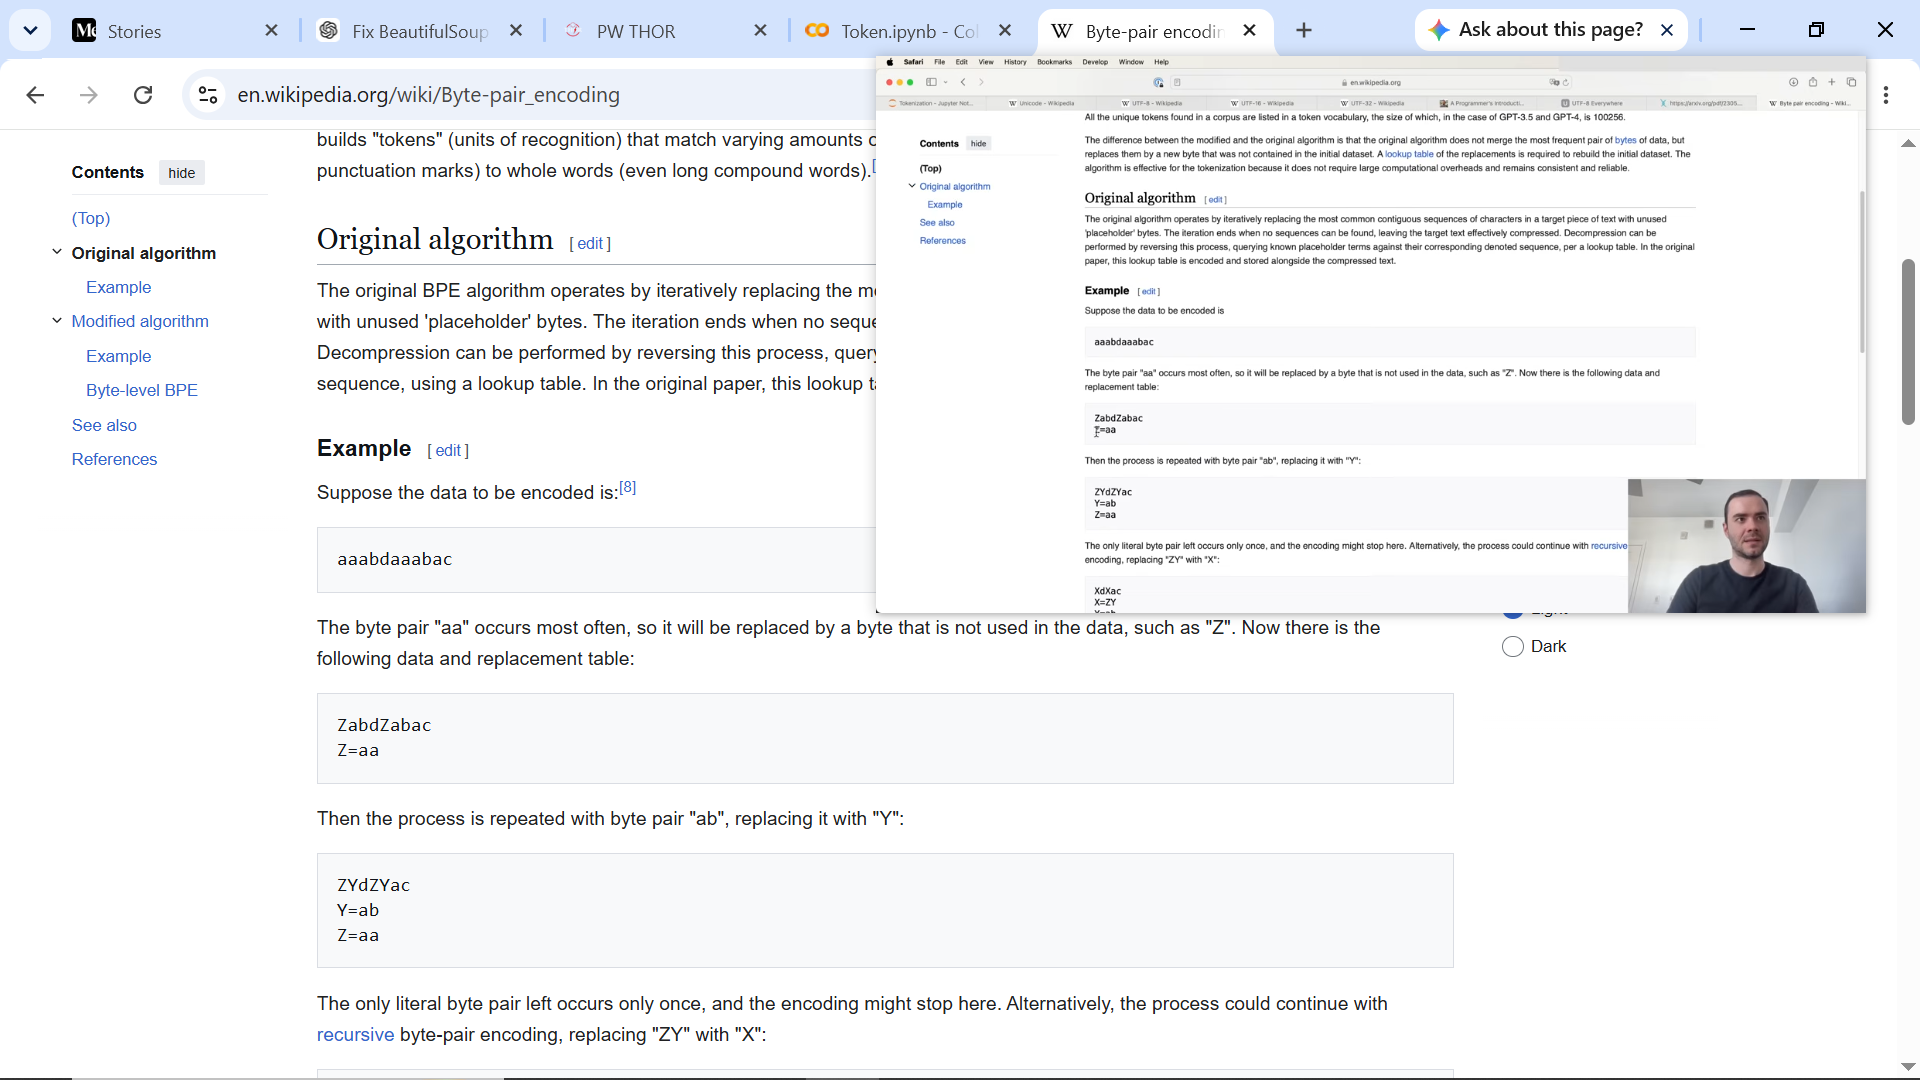

In [ ]:
## we find the pair of the char in te text
## in this we wil decrease the vocab size of the string in the text .

In [ ]:
text = """In computing, byte-pair encoding 😉 (BPE),[1][2] or digram coding,[3] is an algorithm, first described in 1994 by Philip Gage, for encoding strings of text into smaller strings by creating and using a translation table.[4] A slightly modified version of the algorithm is used in large language model tokenizers.

The original version of the algorithm focused on compression. It replaces the highest-frequency pair of bytes with a new byte that was not contained in the initial dataset. A lookup table of the replacements is required to rebuild the initial dataset. The modified version builds "tokens" (units of recognition) that match varying amounts of source text, from single characters (including single digits or single punctuation marks) to whole words (even long compound words).[5][6][7]"""
token = text.encode("utf-8")
token = list(map(int,token))
print(text)
print("length of the text", len(text))
print("=============================")
print(token)
print("length of the token",len(token))

In computing, byte-pair encoding 😉 (BPE),[1][2] or digram coding,[3] is an algorithm, first described in 1994 by Philip Gage, for encoding strings of text into smaller strings by creating and using a translation table.[4] A slightly modified version of the algorithm is used in large language model tokenizers.

The original version of the algorithm focused on compression. It replaces the highest-frequency pair of bytes with a new byte that was not contained in the initial dataset. A lookup table of the replacements is required to rebuild the initial dataset. The modified version builds "tokens" (units of recognition) that match varying amounts of source text, from single characters (including single digits or single punctuation marks) to whole words (even long compound words).[5][6][7]
length of the text 795
[73, 110, 32, 99, 111, 109, 112, 117, 116, 105, 110, 103, 44, 32, 98, 121, 116, 101, 45, 112, 97, 105, 114, 32, 101, 110, 99, 111, 100, 105, 110, 103, 32, 240, 159, 152, 137, 32, 40

In [ ]:
chr(101), chr(32)

('e', ' ')

In [ ]:
def get_stats(ids):
  count = {}
  for pair in zip(ids,ids[1:]):
    count[pair] = count.get(pair,0)+1
  return count

stats = get_stats(token)
print(stats)
print(sorted(((v,k) for k,v in stats.items()), reverse=True))

{(73, 110): 1, (110, 32): 12, (32, 99): 7, (99, 111): 8, (111, 109): 4, (109, 112): 3, (112, 117): 2, (117, 116): 1, (116, 105): 7, (105, 110): 22, (110, 103): 15, (103, 44): 2, (44, 32): 4, (32, 98): 6, (98, 121): 5, (121, 116): 3, (116, 101): 6, (101, 45): 1, (45, 112): 1, (112, 97): 2, (97, 105): 3, (105, 114): 4, (114, 32): 6, (32, 101): 2, (101, 110): 7, (110, 99): 5, (111, 100): 6, (100, 105): 8, (103, 32): 7, (32, 240): 1, (240, 159): 1, (159, 152): 1, (152, 137): 1, (137, 32): 1, (32, 40): 4, (40, 66): 1, (66, 80): 1, (80, 69): 1, (69, 41): 1, (41, 44): 1, (44, 91): 2, (91, 49): 1, (49, 93): 1, (93, 91): 3, (91, 50): 1, (50, 93): 1, (93, 32): 3, (32, 111): 11, (111, 114): 9, (32, 100): 5, (105, 103): 5, (103, 114): 1, (114, 97): 3, (97, 109): 2, (109, 32): 4, (91, 51): 1, (51, 93): 1, (32, 105): 9, (105, 115): 3, (115, 32): 15, (32, 97): 8, (97, 110): 4, (97, 108): 7, (108, 103): 3, (103, 111): 3, (114, 105): 7, (105, 116): 9, (116, 104): 12, (104, 109): 3, (109, 44): 1, (32, 1

In [ ]:
top_pair = max(stats,key=stats.get)
print("the max pair in the :",top_pair)

the max pair in the : (105, 110)


In [ ]:
## when the same pair that is away in the multiple time it should be replace:

In [ ]:
def merge(ids,pair,idx):
  newids = []
  i = 0
  while i < len(ids):
    if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
      newids.append(idx)
      i += 2
    else:
      newids.append(ids[i])
      i += 1
  return newids

print(merge([5,6,6,7,9,1],(6,7),99))
print(merge([5,6,6,7,9,1],(6,6),9))

[5, 6, 99, 9, 1]
[5, 9, 7, 9, 1]


In [ ]:
## in this above this mean that the when the tokenization make same pair then it should be replace by anher digit to
## make it sorter

In [ ]:
token2 = merge(token,top_pair,256)
print(token2)
print("length",len(token2))

[73, 110, 32, 99, 111, 109, 112, 117, 116, 256, 103, 44, 32, 98, 121, 116, 101, 45, 112, 97, 105, 114, 32, 101, 110, 99, 111, 100, 256, 103, 32, 240, 159, 152, 137, 32, 40, 66, 80, 69, 41, 44, 91, 49, 93, 91, 50, 93, 32, 111, 114, 32, 100, 105, 103, 114, 97, 109, 32, 99, 111, 100, 256, 103, 44, 91, 51, 93, 32, 105, 115, 32, 97, 110, 32, 97, 108, 103, 111, 114, 105, 116, 104, 109, 44, 32, 102, 105, 114, 115, 116, 32, 100, 101, 115, 99, 114, 105, 98, 101, 100, 32, 256, 32, 49, 57, 57, 52, 32, 98, 121, 32, 80, 104, 105, 108, 105, 112, 32, 71, 97, 103, 101, 44, 32, 102, 111, 114, 32, 101, 110, 99, 111, 100, 256, 103, 32, 115, 116, 114, 256, 103, 115, 32, 111, 102, 32, 116, 101, 120, 116, 32, 256, 116, 111, 32, 115, 109, 97, 108, 108, 101, 114, 32, 115, 116, 114, 256, 103, 115, 32, 98, 121, 32, 99, 114, 101, 97, 116, 256, 103, 32, 97, 110, 100, 32, 117, 115, 256, 103, 32, 97, 32, 116, 114, 97, 110, 115, 108, 97, 116, 105, 111, 110, 32, 116, 97, 98, 108, 101, 46, 91, 52, 93, 32, 65, 32, 115,

In [ ]:
vocab_size = 276  # the desired final vocabulary size
num_merges = vocab_size - 256

ids = list(token)  # copy so we don't destroy the original list

merges = {}  # (int, int) -> int

for i in range(num_merges):
    stats = get_stats(ids)
    pair = max(stats, key=stats.get)
    idx = 256 + i

    print(f"merging {pair} into a new token {idx}")

    ids = merge(ids, pair, idx)
    merges[pair] = idx

merging (105, 110) into a new token 256
merging (101, 32) into a new token 257
merging (115, 32) into a new token 258
merging (256, 103) into a new token 259
merging (32, 116) into a new token 260
merging (111, 110) into a new token 261
merging (111, 114) into a new token 262
merging (105, 116) into a new token 263
merging (114, 101) into a new token 264
merging (100, 32) into a new token 265
merging (32, 115) into a new token 266
merging (97, 116) into a new token 267
merging (104, 257) into a new token 268
merging (99, 111) into a new token 269
merging (101, 110) into a new token 270
merging (97, 108) into a new token 271
merging (111, 102) into a new token 272
merging (105, 261) into a new token 273
merging (101, 265) into a new token 274
merging (101, 114) into a new token 275


In [ ]:
## Repeatedly find the most frequent adjacent token pair, replace it with a new token ID, an
## remember that replacement rule until the desired vocabulary size is reached.


In [ ]:
print("token_length", len(token))
print("ids_length", len(ids))
print("compression ratio", len(ids)/len(token))

token_length 798
ids_length 602
compression ratio 0.7543859649122807


In [ ]:
## do teh decoing in the

In [ ]:
vocab = {idx: bytes([idx]) for idx in range(256)}
for pair, idx in merges.items():
    vocab[idx] = vocab[pair[0]] + vocab[pair[1]]

def decode(ids):
  token = b"".join(vocab[id] for id in ids)
  return token.decode("utf-8", errors="replace")

print(decode(ids))

In computing, byte-pair encoding 😉 (BPE),[1][2] or digram coding,[3] is an algorithm, first described in 1994 by Philip Gage, for encoding strings of text into smaller strings by creating and using a translation table.[4] A slightly modified version of the algorithm is used in large language model tokenizers.

The original version of the algorithm focused on compression. It replaces the highest-frequency pair of bytes with a new byte that was not contained in the initial dataset. A lookup table of the replacements is required to rebuild the initial dataset. The modified version builds "tokens" (units of recognition) that match varying amounts of source text, from single characters (including single digits or single punctuation marks) to whole words (even long compound words).[5][6][7]


In [ ]:
merges

{(105, 110): 256,
 (101, 32): 257,
 (115, 32): 258,
 (256, 103): 259,
 (32, 116): 260,
 (111, 110): 261,
 (111, 114): 262,
 (105, 116): 263,
 (114, 101): 264,
 (100, 32): 265,
 (32, 115): 266,
 (97, 116): 267,
 (104, 257): 268,
 (99, 111): 269,
 (101, 110): 270,
 (97, 108): 271,
 (111, 102): 272,
 (105, 261): 273,
 (101, 265): 274,
 (101, 114): 275}

In [ ]:
## encoding
def encode(text):
  token = list(text.encode("utf-8"))
  while len(token) >= 2:
    stats = get_stats(token)
    pair = min(stats, key= lambda p: merges.get(p, float("inf")))
    if pair not in merges:
      break
    idx = merges[pair]
    token = merge(token,pair, idx)
  return token

print(encode("g"))

[103]


In [ ]:
print(decode(encode("hello world")))

hello world


In [ ]:
text2 = decode(encode(text))
print(text2 == text)

True


In [ ]:
valtex = """" The original BPE algorithm is modified for use in language modeling, especially for large language models based on neural networks. Compared to the original BPE, the modified BPE does not aim to maximally compress text, but rather, to encode plaintext into "tokens", which are natural numbers.[9] All the unique tokens found in a corpus are listed in a token vocabulary. The token vocabulary can also include some other special tokens, relative to the use case. The size of the token vocabulary, in the case of GPT-3.5 and GPT-4, is 100258 (100000 from BPE algorithm and 258 included as special tokens).[10]

The modified tokenization algorithm initially treats the set of unique characters as 1-character-long n-grams (the initial tokens). Then, successively, the most frequent pair of adjacent tokens is merged into a new, longer n-gram and all instances of the pair are replaced by this new token. This is repeated until a vocabulary of prescribed size is obtained. Note that new words can always be constructed from final vocabulary tokens and initial-set characters.[11]

This modified BPE approach has been extended from spoken language to sign language in recent years."""

In [ ]:
valtex2 = decode(encode(valtex))
print(valtex2 == valtex)

True


In [ ]:
## that is the basic of byte pair
## series

#### here it should be the link that can be verify teh tokenization
[tokinizer](https://tiktokenizer.vercel.app/)

### split using regex funtion using the (gpt series)

In [ ]:
import regex as re

In [ ]:
gpt2path = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")
print(re.findall(gpt2path, "Hello world123 how are you"))


['Hello', ' world', '123', ' how', ' are', ' you']


In [ ]:
example = """
for i in range(1,100):
  if i % 3 == 0 and i % 5 == 0:
    print("fuzzyBuzz)
  elif i % 3 == 0:
    print("fizz")
  elif i % 5 == 0:
    print("Buzz")
  else:
    print(i)
"""

print(re.findall(gpt2path, example))



['\n', 'for', ' i', ' in', ' range', '(', '1', ',', '100', '):', '\n ', ' if', ' i', ' %', ' 3', ' ==', ' 0', ' and', ' i', ' %', ' 5', ' ==', ' 0', ':', '\n   ', ' print', '("', 'fuzzyBuzz', ')', '\n ', ' elif', ' i', ' %', ' 3', ' ==', ' 0', ':', '\n   ', ' print', '("', 'fizz', '")', '\n ', ' elif', ' i', ' %', ' 5', ' ==', ' 0', ':', '\n   ', ' print', '("', 'Buzz', '")', '\n ', ' else', ':', '\n   ', ' print', '(', 'i', ')', '\n']


In [ ]:
import tiktoken
## that is does not merge space in gpt 2
enc = tiktoken.get_encoding("gpt2")
print(enc.encode("    hello world"))

## that help to merge the space of between the text
enc = tiktoken.get_encoding("cl100k_base")
print(enc.encode("   hello world"))

[220, 220, 220, 23748, 995]
[256, 24748, 1917]


In [ ]:
# to download these two files:
!wget https://openaipublic.blob.core.windows.net/gpt-2/models/1558M/vocab.bpe
!wget https://openaipublic.blob.core.windows.net/gpt-2/models/1558M/encoder.json

--2026-09-09 15:51:52--  https://openaipublic.blob.core.windows.net/gpt-2/models/1558M/vocab.bpe
Resolving openaipublic.blob.core.windows.net (openaipublic.blob.core.windows.net)... 57.150.97.129
Connecting to openaipublic.blob.core.windows.net (openaipublic.blob.core.windows.net)|57.150.97.129|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 456318 (446K) [application/octet-stream]
Saving to: ‘vocab.bpe.2’

vocab.bpe.2         100%[===================>] 445.62K  1.29MB/s    in 0.3s    

2026-09-09 15:51:52 (1.29 MB/s) - ‘vocab.bpe.2’ saved [456318/456318]

--2026-09-09 15:51:52--  https://openaipublic.blob.core.windows.net/gpt-2/models/1558M/encoder.json
Resolving openaipublic.blob.core.windows.net (openaipublic.blob.core.windows.net)... 57.150.97.129
Connecting to openaipublic.blob.core.windows.net (openaipublic.blob.core.windows.net)|57.150.97.129|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1042301 (1018K) [application/json]
Sav

In [ ]:
import os, json

with open('encoder.json', 'r') as f:
    encoder = json.load(f)

with open('vocab.bpe', 'r', encoding='utf-8') as f:
    bpe_data = f.read()

bpe_merges = [tuple(merge_str.split()) for merge_str in bpe_data.split('\n')[1:-1]]

In [ ]:
## special token

In [ ]:
len(encoder)

50257

In [ ]:
encoder['<|endoftext|>']   ## that is limit of the document is ended

50256

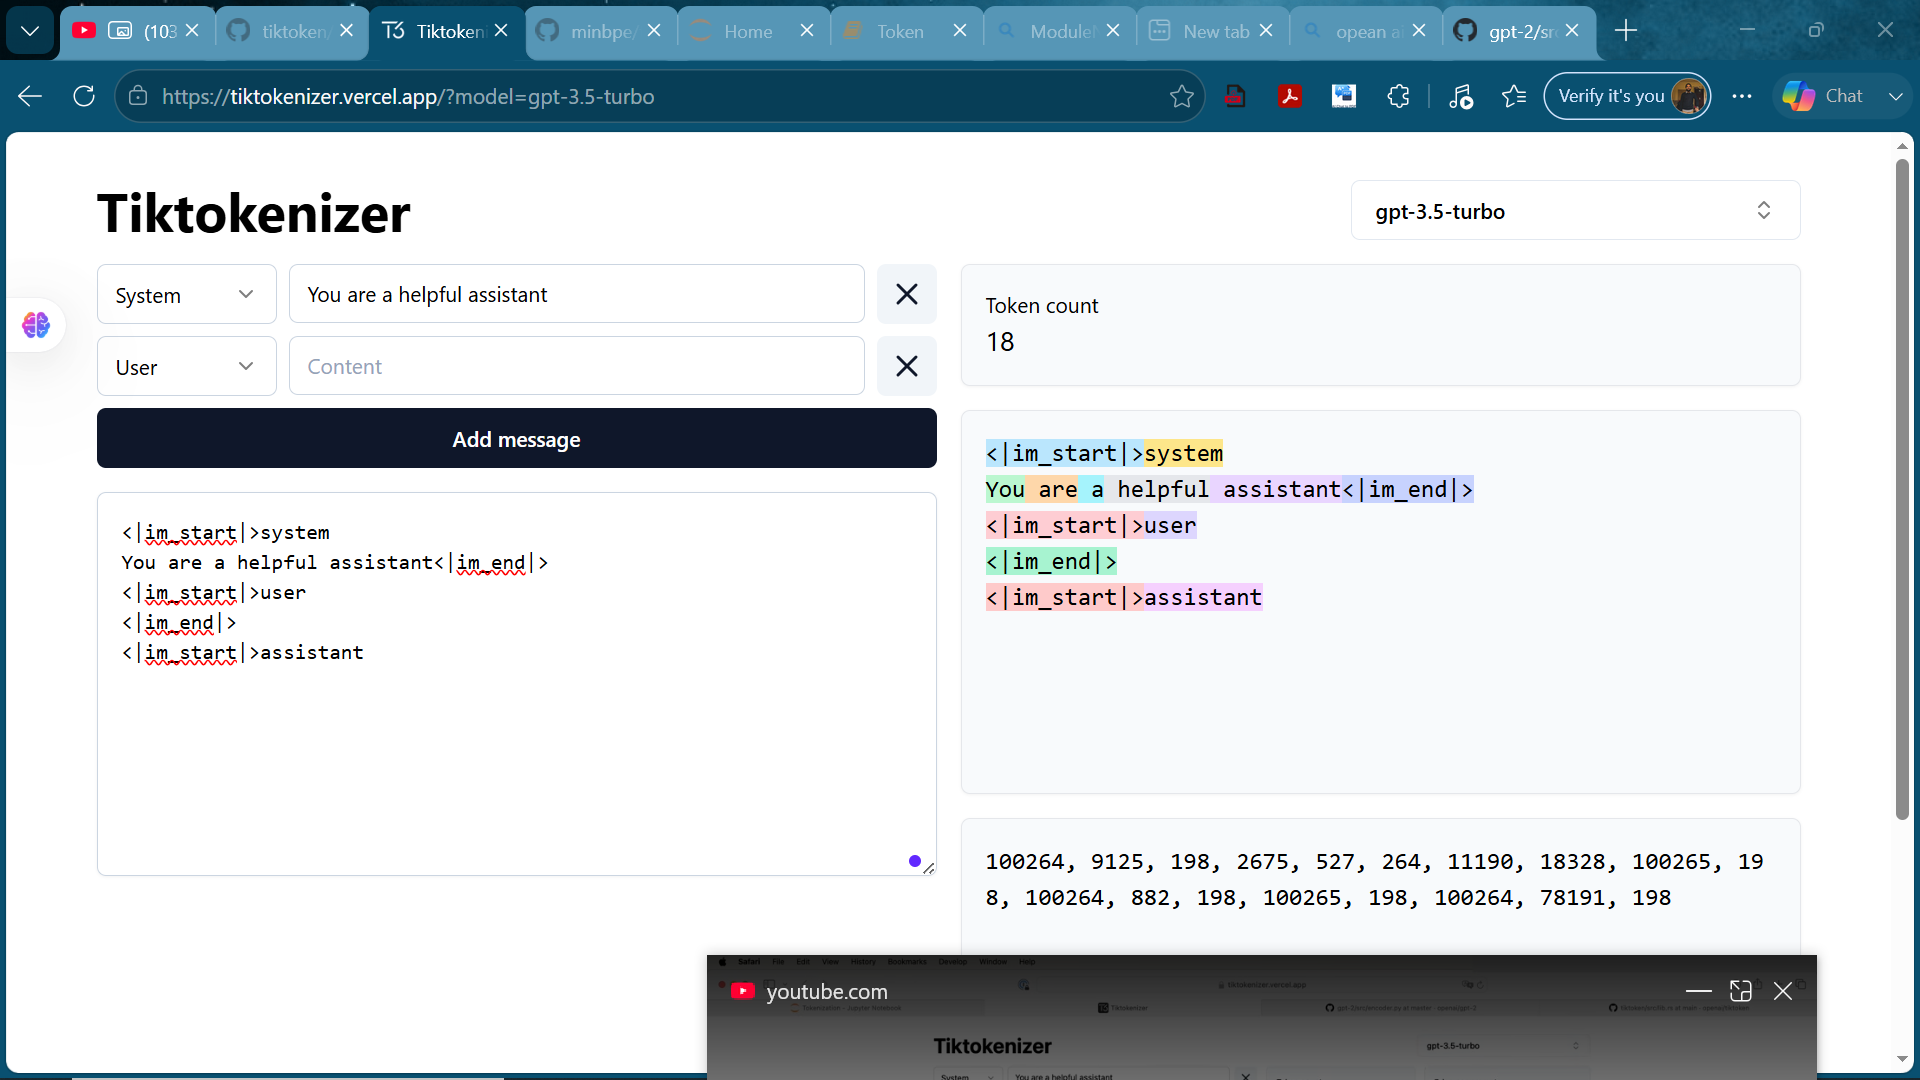

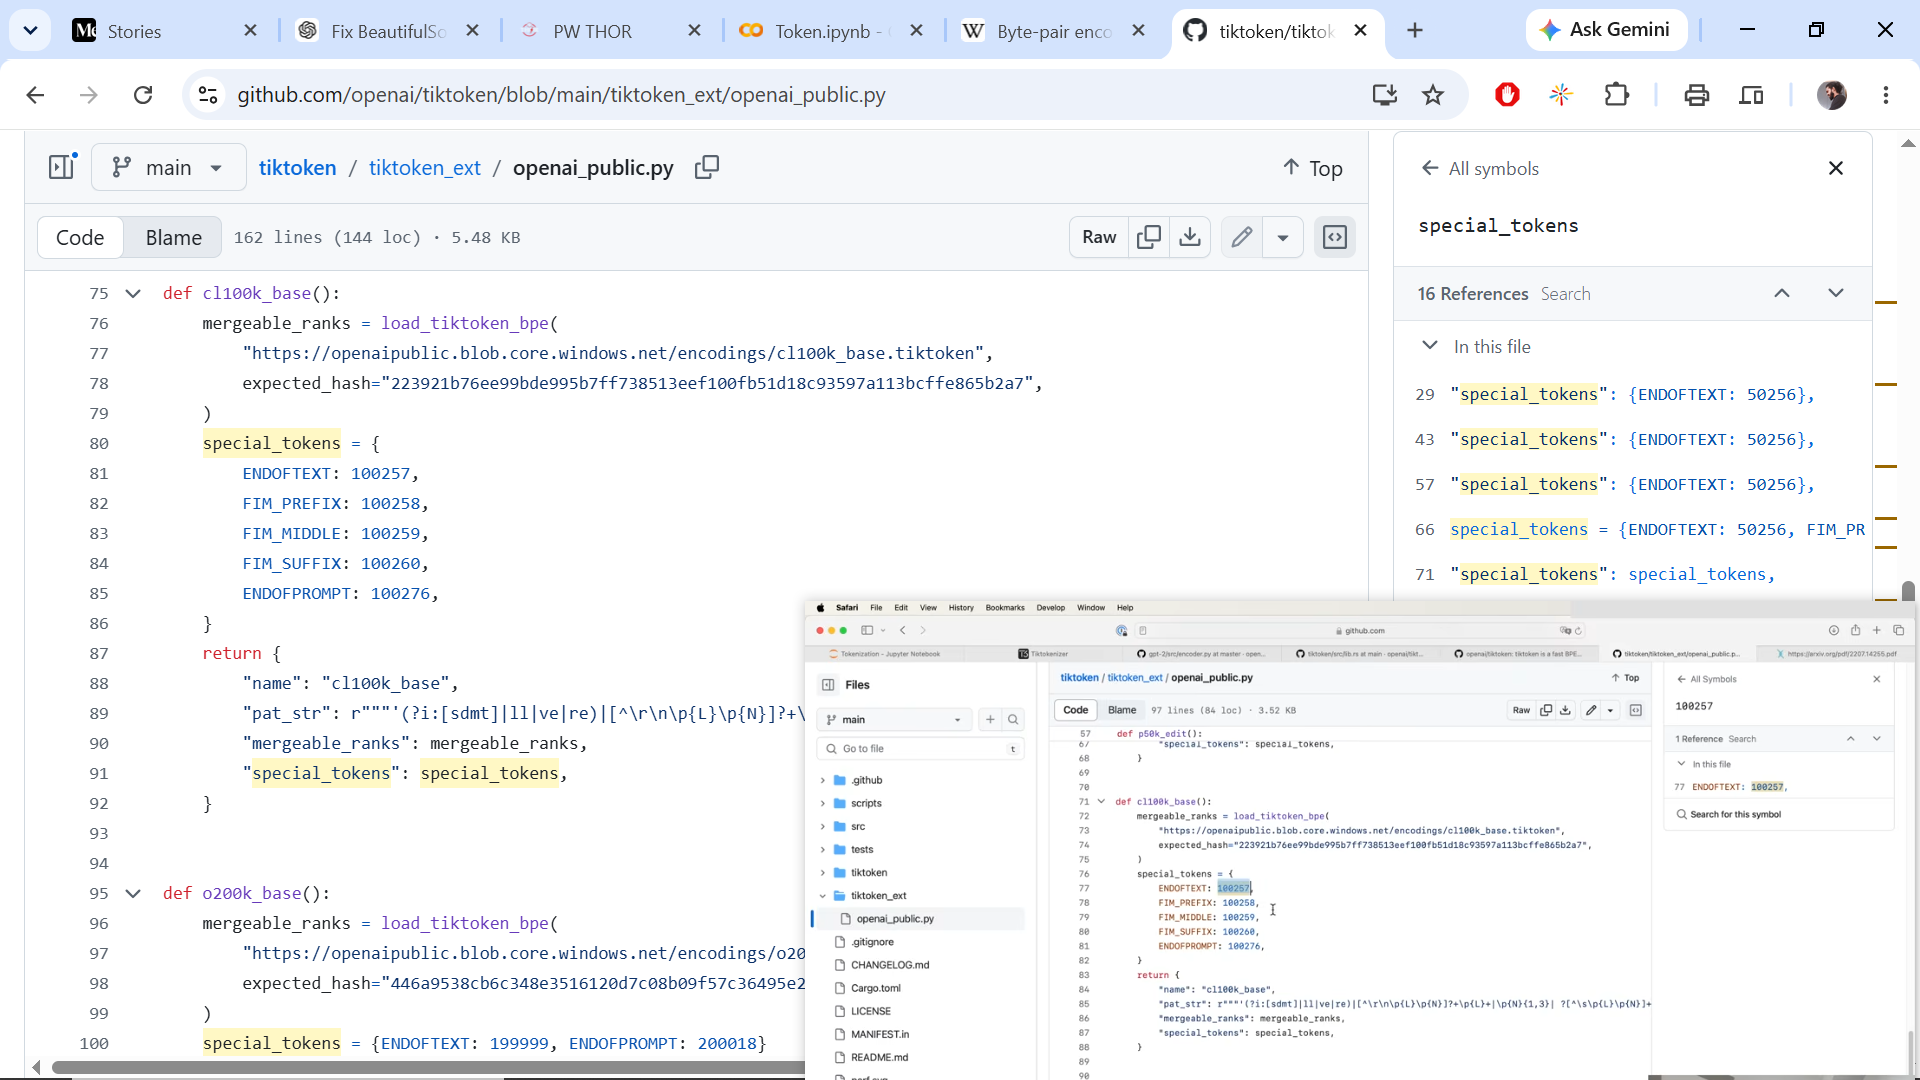

In [ ]:
## these are the special token that is use in the gpt model
# We use special tokens in a tokenizer/LLM to represent information that normal words or punctuation cannot reliably represent.

### MINBPE Exercise

[follow this ]https://github.com/karpathy/minbpe/blob/master/exercise.md)

In [ ]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")   # gpt 4
encoded_text = enc.encode("hello vivek kumar")
print(encoded_text)
print(enc.decode(encoded_text) == "hello vivek kumar")

[15339, 93002, 74, 597, 31967]
True
